# 01. Exploratory Data Analysis & Credit Risk Portfolio Audit

### Project: Fintech Credit Risk & Loan Portfolio Vintage Analysis

**Objective:** Ingest the raw multi-year loan portfolio dataset (100,000+ borrowers), conduct schema and data integrity audits, examine borrower credit distributions (FICO, DTI, Annual Income), assess terminal loan outcomes, and diagnose inter-variable risk correlations.


## 1. Environment Setup & Raw Portfolio Ingestion

We import standard analytics libraries and ingest `loan_portfolio_raw.csv`.


In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

DATA_PATH = 'data/loan_portfolio_raw.csv'
df = pd.read_csv(DATA_PATH)
print(f'Ingested {len(df):,} loan accounts.')
print(f'Total Funded Capital: ${df["LoanAmount"].sum():,.2f}')
print(f'Unique Borrowers    : {df["BorrowerID"].nunique():,}')


Ingested 105,000 loan accounts.
Total Funded Capital: $1,660,087,000.00
Unique Borrowers    : 105,000


## 2. Schema Structure & Attribute Types Audit

Review column data types and verify memory consumption.


In [2]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 105000 entries, 0 to 104999
Data columns (total 31 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   LoanID                105000 non-null  str    
 1   BorrowerID            105000 non-null  str    
 2   LoanAmount            105000 non-null  int64  
 3   Term                  105000 non-null  str    
 4   InterestRate          105000 non-null  float64
 5   Installment           105000 non-null  float64
 6   Grade                 105000 non-null  str    
 7   SubGrade              105000 non-null  str    
 8   FicoScore             105000 non-null  int64  
 9   AnnualIncome          105000 non-null  float64
 10  DTI                   105000 non-null  float64
 11  EmploymentLength      105000 non-null  str    
 12  HomeOwnership         105000 non-null  str    
 13  VerificationStatus    105000 non-null  str    
 14  IssueDate             105000 non-null  str    
 15  Vintage    

## 3. High-Level Portfolio Summary Metrics

We inspect the first 5 records across core underwriting dimensions.


In [3]:
df[['LoanID', 'BorrowerID', 'LoanAmount', 'InterestRate', 'Grade', 'FicoScore', 'DTI', 'LoanStatus']].head()


,LoanID,BorrowerID,LoanAmount,InterestRate,Grade,FicoScore,DTI,LoanStatus
0,LN-1000000,BW-5000000,15000,12.11,B,710,7.09,Fully Paid
1,LN-1000001,BW-5000001,3000,25.54,F,620,34.21,Current
2,LN-1000002,BW-5000002,15000,18.30,D,635,19.52,Current
3,LN-1000003,BW-5000003,3000,14.41,C,690,19.57,Fully Paid
4,LN-1000004,BW-5000004,30000,6.88,A,761,9.95,Fully Paid


## 4. Borrower Credit Score (FICO) Distribution Across Risk Grades

Visualizing borrower credit scores across credit rating grades A through G.


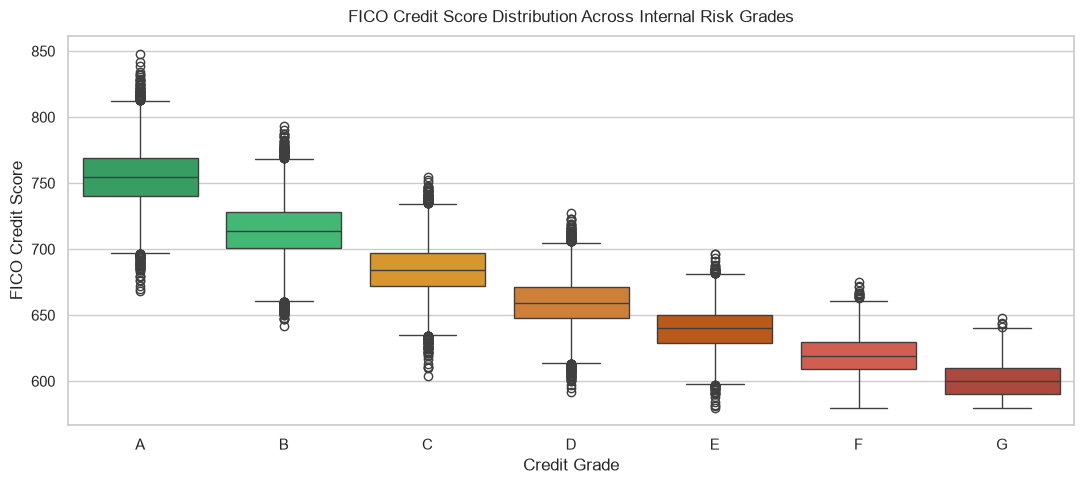

In [4]:
plt.figure(figsize=(11, 5))
palette_grades = {'A': '#27ae60', 'B': '#2ecc71', 'C': '#f39c12', 'D': '#e67e22', 'E': '#d35400', 'F': '#e74c3c', 'G': '#c0392b'}
sns.boxplot(data=df, x='Grade', y='FicoScore', order=['A','B','C','D','E','F','G'], palette=palette_grades)
plt.title('FICO Credit Score Distribution Across Internal Risk Grades', fontsize=12, pad=10)
plt.xlabel('Credit Grade')
plt.ylabel('FICO Credit Score')
plt.tight_layout()
plt.show()


## 5. Debt-to-Income (DTI) and Funded Loan Amount Distributions

We evaluate the distribution of loan amounts and debt burden ratios.


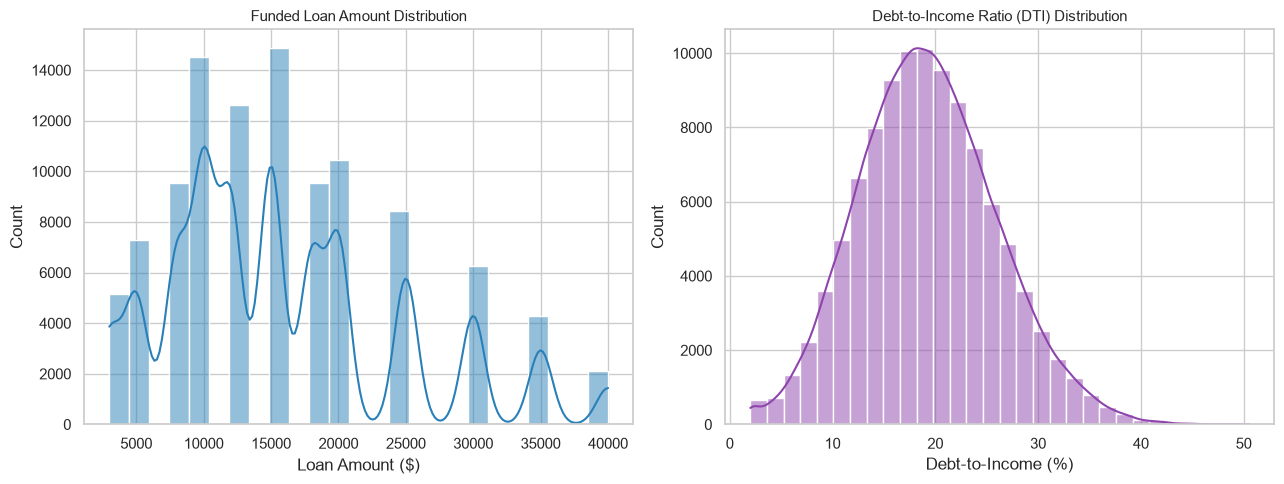

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df['LoanAmount'], bins=25, kde=True, color='#2980b9', ax=ax1)
ax1.set_title('Funded Loan Amount Distribution', fontsize=11)
ax1.set_xlabel('Loan Amount ($)')

sns.histplot(df['DTI'], bins=30, kde=True, color='#8e44ad', ax=ax2)
ax2.set_title('Debt-to-Income Ratio (DTI) Distribution', fontsize=11)
ax2.set_xlabel('Debt-to-Income (%)')

plt.tight_layout()
plt.show()


## 6. Portfolio Status & Terminal Loan Outcome Volumes

Tabulating loan accounts across terminal performance statuses.


In [6]:
status_counts = df['LoanStatus'].value_counts().reset_index()
status_counts.columns = ['LoanStatus', 'LoanCount']
status_counts['Share_Pct'] = (status_counts['LoanCount'] / status_counts['LoanCount'].sum() * 100).round(2)
status_counts


,LoanStatus,LoanCount,Share_Pct
0,Fully Paid,63545,60.52
1,Current,25450,24.24
2,Charged Off,11954,11.38
3,Default,1834,1.75
4,Late (31-120 days),1558,1.48
5,In Grace Period,659,0.63


## 7. Correlation Heatmap of Quantitative Financial Risk Variables

Evaluating linear correlations between underwriting parameters (FICO, DTI, Interest Rate, Revolving Utilization, Inquiries, Write-Offs).


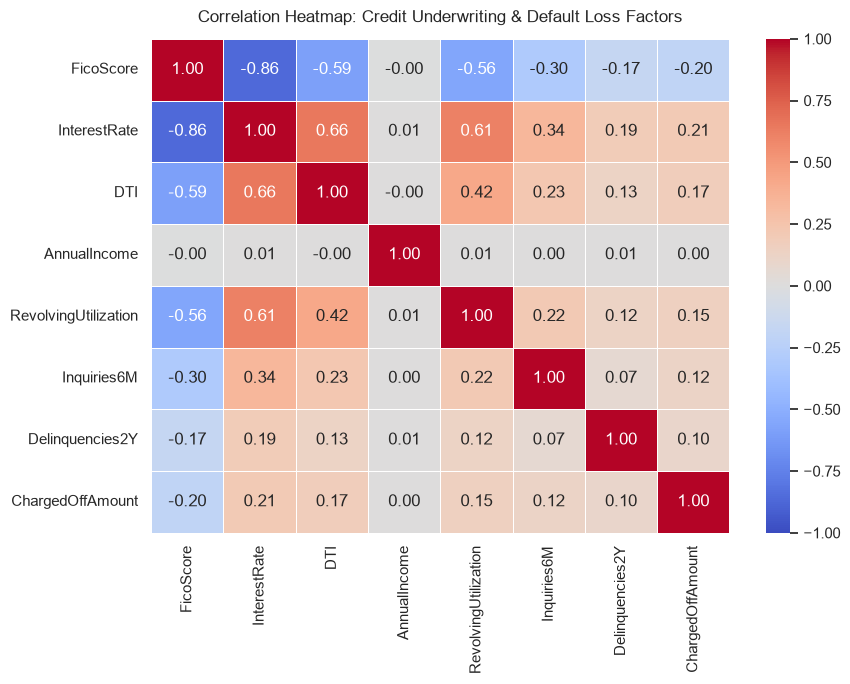

In [7]:
num_cols = ['FicoScore', 'InterestRate', 'DTI', 'AnnualIncome', 'RevolvingUtilization', 'Inquiries6M', 'Delinquencies2Y', 'ChargedOffAmount']
corr_matrix = df[num_cols].corr().round(3)

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap: Credit Underwriting & Default Loss Factors', fontsize=12, pad=12)
plt.tight_layout()
plt.show()
